# Cuadratura Adaptable

### $\int_a^b f(x)=S(a,b)-\frac{h^5}{90}f^{(4)}(\xi)$

### Donde:
$s(a,b)=\frac{h}{3}[f(a)+4f(a+h)+f(b)]$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def adaptable(f, a, b, tol, todo, fa, fb, fm, profundidad):
    
    m = (a + b) / 2
    h = (b - a) / 4
    
    # Puntos medios en los subintervalos izquierdo y derecho
    izq_m = (a + m) / 2
    der_m = (m + b) / 2
    
    flm = f(izq_m)
    frm = f(der_m)
    
    # Reglas de Simpson en las mitades izquierda y derecha
    izq = (h / 3) * (fa + 4 * flm + fm)
    der = (h / 3) * (fm + 4 * frm + fb)
    
    # Valor aproximado
    s = izq + der
    
    # Criterio de tolerancia 
    if abs(s - todo) < 15 * tol or profundidad <= 0:
        # Se aplica corrección y se retorna el valor junto con el intervalo
        return s + (s - todo) / 15.0, [a, b]
    else:
        # Llamada recursiva 
        res_izq, intervalos_izq = adaptable(f, a, m, tol / 2, izq, fa, fm, flm, profundidad - 1)
        res_der, intervalos_der = adaptable(f, m, b, tol / 2, der, fm, fb, frm, profundidad - 1)
        return res_izq + res_der, intervalos_izq + intervalos_der

def cuadratura_adaptable(f, a, b, tol, profundidad_max=90):
   
    m = (a + b) / 2
    h = (b - a) / 2
    fa = f(a)
    fb = f(b)
    fm = f(m)
    
    # Aproximación inicial de Simpson en el intervalo [a, b]
    todo = (h / 3) * (fa + 4 * fm + fb)
    
    # Ejecución de la rutina recursiva
    valor_aprox, subintervalos = adaptable(f, a, b, tol, todo, fa, fb, fm, profundidad_max)
    
    # Procesar y limpiar los subintervalos generados
    subintervalos = np.array(subintervalos).reshape(-1, 2)
    intervalos_unicos = np.unique(subintervalos, axis=0)
    
    return valor_aprox, intervalos_unicos

In [ ]:
# Definición de la función del libro
def funcion(x):
    return (100/x**2)*(np.sin(10/x))

limite_a = 1
limite_b = 3
tolerancia = 1e-4

# Ejecutar el algoritmo de cuadratura adaptable
integral_aproximada, malla_intervalos = cuadratura_adaptable(funcion, limite_a, limite_b, tolerancia)

print(f"Valor aprox: {integral_aproximada:.8f}")
print(f"Número de subintervalos adaptativos generados: {len(malla_intervalos)}")

Valor aprox: -1.42602469
Número de subintervalos adaptativos generados: 22


### Gráfica

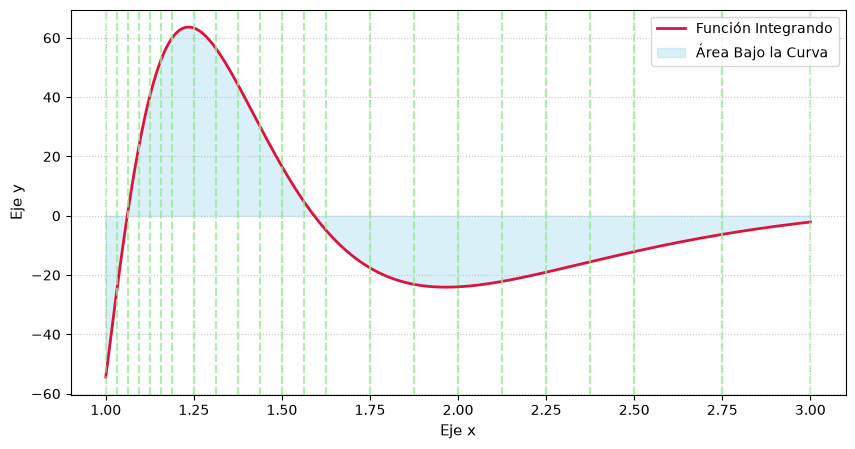

In [ ]:
x_vals = np.linspace(limite_a, limite_b, 1000)
y_vals = funcion(x_vals)

plt.figure(figsize=(10, 5))
plt.plot(x_vals, y_vals, label='Función Integrando', color='crimson', linewidth=2)

# Líneas divisorias de los subintervalos adaptativos
for intervalo in malla_intervalos:
    # Usando 'lightgreen' para las líneas
    plt.axvline(intervalo[0], color='lightgreen', linestyle='--', alpha=0.5)
    plt.axvline(intervalo[1], color='lightgreen', linestyle='--', alpha=0.5)

plt.fill_between(x_vals, y_vals, color='skyblue', alpha=0.3, label='Área Bajo la Curva')
plt.xlabel('Eje x', fontsize=11)
plt.ylabel('Eje y', fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()